# Non-reciprocal optical binding: exceptional points and limit cycles (after Reisenbauer et al. 2024)

M. Reisenbauer, H. Rudolph, L. Egyed, K. Hornberger, A. V. Zasedatelev, M. Abuzarli, B. A. Stickler and
U. Delić, *Non-Hermitian dynamics and non-reciprocity of optically coupled nanoparticles*, Nat. Phys.
**20**, 1629 (2024), [doi:10.1038/s41567-024-02589-8](https://doi.org/10.1038/s41567-024-02589-8).

Two silica spheres in two phase-coherent tweezers 18.4 μm apart are coupled by optical binding. The
optical phase difference is set so that the coupling along the tweezer axes is purely
**anti-reciprocal** ($g_r = 0$, $g_a \neq 0$): particle 2 pushes particle 1 with the rate $+g_a$ and particle
1 pushes particle 2 with $-g_a$. Detuning the two trap frequencies by $\Delta\Omega$ then gives a
non-Hermitian two-mode system (their Eq. (2)) with exceptional points (EPs) at $\Delta\Omega = 0$ and
$4g_a$. Between the EPs the eigenfrequencies coalesce and one collective mode is amplified. When its
gain exceeds the gas damping, the motion grows until the nonlinearity of the binding force itself
saturates it on a **limit cycle**, whose amplitude the paper predicts with a cycle-averaged model
(their Eq. (3), with $f(x) = 2J_1(x)/x$).

This notebook uses levisim's `OpticalBinding` interaction for both regimes:

1. the coupling constant $g_a$ against the paper's closed form (Methods, Eq. (M2)),
2. the EPs from the eigenvalues of levisim's linear drift matrix (`MultiTrap(interactions=[...])`,
   no rotating-wave approximation), against $\Delta\Omega_\mathrm{EP} = 0, 4g_a$ and the measured range of
   degenerate frequencies in Fig. 3a,
3. the limit-cycle amplitude and phase delay from the nonlinear time domain
   (`MultiParticleFreeSpaceSimulation` with the full binding force), against Eq. (3),
4. a noisy run at the paper's gas damping, the analogue of the bottom row of Fig. 2.

The companion experiment of Liška et al., Nat. Phys. **20**, 1622 (2024), uses counter-propagating
standing-wave traps at 1550 nm with 305 nm radius particles ($kR \approx 1.2$, outside the point-dipole
regime); levisim's tweezers are single focused beams, so it is not reproduced here.

In [ ]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.signal import hilbert
from scipy.special import j1

from levisim.core.constants import π, ε0
from levisim.core.units import kHz, mbar, nm, μm, μs
from levisim.core.logger import logger
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.physics import Bead, Gas, OpticalBinding, Trap, Tweezer
from levisim.multiphysics.multitrap import MultiTrap
from levisim.multiphysics.covariance import quadrature_matrices
from levisim.simulation import MultiParticleFreeSpaceSimulation

set_plt_rcParams_to_xmgrace_style()
logger.remove()
T_START = time.time()

λ = 1064 * nm
k = 2 * π / λ
R = 105 * nm                    # nominal radius 105 ± 2 nm
wx, wy = 0.678 * μm, 0.775 * μm  # tweezer waists (Methods, from the measured frequencies)
d0 = 18.408 * μm                # Methods, (18.408 ± 0.005) μm
Ω0 = 27.5 * kHz                 # mean z frequency
γ = 0.46 * kHz                  # gas damping, (0.46 ± 0.02) kHz
P_nominal = 0.3                 # P1,2 ≈ 0.3 W

# levisim's paraxial Gaussian trap at 0.3 W is stiffer than the NA = 0.77 focus; the power is scaled so
# that the trap has the measured Ω0 (the field at the particle then follows from the trap itself)
Ω_paraxial = Trap(bead=Bead(r=R), tweezer=Tweezer(Power=P_nominal, wx0=wx, wy0=wy)).Ωj['z']
P0 = P_nominal * (Ω0 / Ω_paraxial)**2
print(f'paraxial Ωz/2π at {P_nominal} W: {Ω_paraxial/kHz:.1f} kHz; power giving Ω0/2π = 27.5 kHz: P0 = {P0*1e3:.1f} mW')


def traps(η=0.0, θ=0.0, gas=None, feedback=True):
    """Powers P0(1 ∓ η) (so ΔΩ = Ω2 - Ω1 ≈ η·Ω0), separation d0 along (cos θ, sin θ, 0), φ2 - φ1 = -π/2.
    feedback=True: the damping γ is cold damping on every axis and the gas is at 1e-9 mbar (no noise)"""
    gas = gas or Gas(P=1e-9 * mbar)
    damping = dict(Γ_fbx=γ, Γ_fby=γ, Γ_fbz=γ) if feedback else dict(Γ_fbx=0.0, Γ_fby=0.0, Γ_fbz=0.0)
    axis = np.array([np.cos(θ), np.sin(θ), 0.0])
    return [Trap(bead=Bead(r=R), tweezer=Tweezer(Power=P0 * (1 - η), wx0=wx, wy0=wy, φ=0.0), gas=gas, **damping),
            Trap(bead=Bead(r=R), tweezer=Tweezer(Power=P0 * (1 + η), wx0=wx, wy0=wy, φ=-π/2), gas=gas, position=tuple(d0 * axis),
                 **damping)]


def coupling_rates(trap_list, field='gaussian'):
    """(g_r, g_a) of the z modes from the linearised binding: g_jk = -K_jk/(2mΩ0); g_r ± g_a = g_12, g_21"""
    binding = OpticalBinding(traps=trap_list, tweezer_field=field)
    K = binding.stiffness_blocks(np.array([t.position for t in trap_list]), [t.bead for t in trap_list])
    m = trap_list[0].bead.m
    g12, g21 = -K[0, 1, 2, 2] / (2 * m * Ω0), -K[1, 0, 2, 2] / (2 * m * Ω0)
    return (g12 + g21) / 2, (g12 - g21) / 2

paraxial Ωz/2π at 0.3 W: 71.3 kHz; power giving Ω0/2π = 27.5 kHz: P0 = 44.6 mW


## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| wavelength | 1064 nm | Experimental setup |
| radius | 105 nm (silica, levisim's default material) | Experimental setup, $r = (105 \pm 2)$ nm |
| waists | $w_x$ = 0.678 μm, $w_y$ = 0.775 μm | Methods (from the measured frequencies) |
| separation | $d_0$ = 18.408 μm | Methods |
| mean frequency | $\Omega_0/2\pi$ = 27.5 kHz (power scaled to give it, see above) | Experimental setup |
| gas damping | $\gamma/2\pi$ = 0.46 kHz | Experimental setup |
| phase | $\phi_2 - \phi_1 = -\pi/2$, so that $g_r = 0$ | main text ("we set $d_0$ and $\Delta\phi$ such that $g_r$ is negligible") |
| coupling strength | set with the angle $\theta$ of the separation axis to the $x$ axis ($G\propto\cos^2\theta$) | main text: the paper turns the polarisation with a half-wave plate |

**Conventions.** levisim's $g_r \pm g_a$ are `G[z1, z2]` and `G[z2, z1]` (the rate at which particle 2
drives 1 and 1 drives 2), as in the paper's $H_\mathrm{NH}$. The paper defines $\Delta\phi = \phi_2 - \phi_1$ but
Rieser et al. (2022) and Rudolph et al. (2024) use $\phi_1 - \phi_2$ in the same expression for $g_a$;
levisim reproduces the latter (field $\propto e^{i\phi}$, `Tweezer.φ`), so $g_a > 0$ here needs
$\phi_2 - \phi_1 = -\pi/2$. Only the sign of $g_a$ relative to $\Delta\Omega$ matters for what follows.

## 1. The coupling constant

The paper's Eq. (M2), $g_a = G\sin(kd_0)\sin\Delta\phi/kd_0$ with $G = \varepsilon_0\chi^2V^2k^5E_0^2/(16\pi m\Omega_0)\cos^2\theta$,
keeps the plane-wave part of the tweezer fields. levisim's Gaussian tweezers carry the Gouy phase,
whose gradient at the focus is $k' = k - 1/z_R$ instead of $k$ (Rudolph et al., PRL **133**, 233603 (2024),
Eq. (A4)), which lowers $g_a$ by $(k'/k)^2$. Compared (stated before computing): levisim's plane-wave
option against Eq. (M2) (expected to agree up to $O(1/kd_0)$ and the radiation reaction), and the
largest $g_a/\gamma$ that levisim allows ($\theta = 0$) against the largest measured value,
$g_a/\gamma = 1.04 \pm 0.08$ (Fig. 2).

In [ ]:
t0 = traps()
tweezer, bead = t0[0].tweezer, t0[0].bead
χV = np.real(tweezer.effective_polarisability(bead)) / ε0
G_M2 = ε0 * χV**2 * k**5 * tweezer.E0**2 / (16 * π * bead.m * Ω0)
ga_M2 = abs(G_M2 * np.sin(k * d0) / (k * d0))
ga_max = {}
for field in ('plane_wave', 'gaussian'):
    gr, ga = coupling_rates(t0, field)
    ga_max[field] = ga
    print(f'{field:10s}: g_r/2π = {gr/kHz*1e3:+.3f} Hz, g_a/2π = {ga/kHz*1e3:.1f} Hz = {ga/γ:.3f} γ; '
          f'Eq. (M2): {ga_M2/kHz*1e3:.1f} Hz; ratio {ga/ga_M2:.4f}')
print(f"(k'/k)² = {(1 - 1/(k*tweezer.zR))**2:.4f} with zR = {tweezer.zR/μm:.3f} μm (paper: 1.55 μm)")


def angle_for(ga_target, field='gaussian'):
    """Angle θ of the separation axis that gives g_a = ga_target (g_a ∝ cos²θ)"""
    return float(np.arccos(np.sqrt(ga_target / ga_max[field])))

plane_wave: g_r/2π = +0.000 Hz, g_a/2π = 574.4 Hz = 1.249 γ; Eq. (M2): 590.9 Hz; ratio 0.9720
gaussian  : g_r/2π = -0.000 Hz, g_a/2π = 456.2 Hz = 0.992 γ; Eq. (M2): 590.9 Hz; ratio 0.7721
(k'/k)² = 0.7936 with zR = 1.551 μm (paper: 1.55 μm)


## 2. Exceptional points from the linear drift matrix (Fig. 3a)

Published: for $g_a/\gamma = 0.58 \pm 0.05$ the eigenfrequencies are degenerate for
$0 < \Delta\Omega/\gamma \lesssim 2.3$ (Fig. 3a), i.e. between the EPs at 0 and $4g_a$. The damping rates of the
two modes split maximally, by $4g_a$, at $\Delta\Omega = 2g_a$ (main text). levisim: `MultiTrap` with the
same traps (gas damping set to $\gamma$ through the pressure) and the eigenvalues of the
mechanical drift matrix without the cavity (`quadrature_matrices(mtrap, cavity=False)`).

gas pressure for γ: 0.742 mbar; MultiTrap Γz/2π = 0.460 kHz
θ = 40.1°: MultiTrap g_a/γ = 0.583, g_r/γ = +0.0e+00 (rates with the shifted Ω; the target 0.58 used Ω0)
levisim: degenerate frequencies for 0.030 ≤ ΔΩ/γ ≤ 2.332; 4 g_a/γ = 2.332 (paper: 0 < ΔΩ/γ ≲ 2.3, 4 g_a/γ = 2.32)
largest damping splitting 3.998 g_a at ΔΩ = 2.051 g_a (paper: 4 g_a at ΔΩ = 2 g_a)


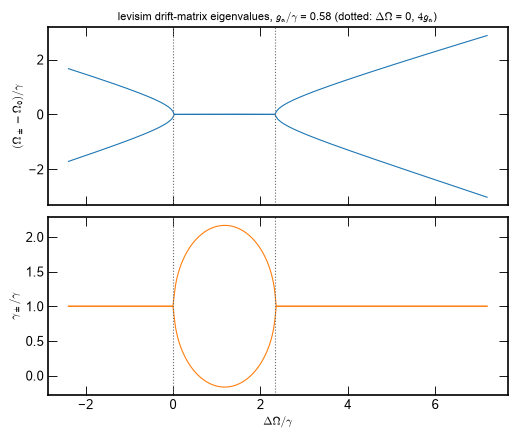

In [ ]:
Γ_per_mbar = Trap(bead=Bead(r=R), gas=Gas(P=1 * mbar)).Γth
P_gas = γ / Γ_per_mbar * mbar
θ_058 = angle_for(0.58 * γ)


def eigen(η):
    trap_list = traps(η, θ_058)
    mtrap = MultiTrap(
        num_traps=2, Cartesian_axes_per_trap=3, tweezers=[t.tweezer for t in trap_list],
        beads=[Bead(r=R, Φ=π/2), Bead(r=R, Φ=π/2)], trap_positions=[t.position for t in trap_list],
        interactions=[OpticalBinding()], static_cavity_shifts=False, gas_kwargs={'P': P_gas / mbar * mbar},
        photon_recoil=False,
    )
    A, _ = quadrature_matrices(mtrap, cavity=False)
    labels = mtrap.labels
    index = [i for label in ('z1', 'z2') for i in (2 * labels.index(label), 2 * labels.index(label) + 1)]
    ev = np.linalg.eigvals(A[np.ix_(index, index)])
    ev = ev[ev.imag > 0]
    ΔΩ = trap_list[1].Ωj['z'] - trap_list[0].Ωj['z']
    return ΔΩ, ev[np.argsort(ev.imag)], mtrap


_, _, m058 = eigen(0.0)
print(f'gas pressure for γ: {P_gas/mbar:.3f} mbar; MultiTrap Γz/2π = {m058.dimensions["z1"].Γ/kHz:.3f} kHz')
L = m058.labels
G = m058.mechanical_coupling_matrix
ga_mt = (G[L.index('z1'), L.index('z2')] - G[L.index('z2'), L.index('z1')]) / 2
gr_mt = (G[L.index('z1'), L.index('z2')] + G[L.index('z2'), L.index('z1')]) / 2
print(f'θ = {np.degrees(θ_058):.1f}°: MultiTrap g_a/γ = {ga_mt/γ:.3f}, g_r/γ = {gr_mt/γ:+.1e} '
      f'(rates with the shifted Ω; the target 0.58 used Ω0)')

ηs = np.linspace(-0.04, 0.12, 321)
rows = [eigen(η) for η in ηs]
ΔΩs = np.array([r[0] for r in rows])
evs = np.array([r[1] for r in rows])
freq_split = np.diff(evs.imag, axis=1)[:, 0]
degenerate = ΔΩs[freq_split < 1e-3 * γ]
damping = np.sort(-2 * evs.real, axis=1)
print(f'levisim: degenerate frequencies for {degenerate.min()/γ:.3f} ≤ ΔΩ/γ ≤ {degenerate.max()/γ:.3f}; '
      f'4 g_a/γ = {4*ga_mt/γ:.3f} (paper: 0 < ΔΩ/γ ≲ 2.3, 4 g_a/γ = 2.32)')
i_max = np.argmax(abs(np.diff(damping, axis=1)[:, 0]))
print(f'largest damping splitting {abs(np.diff(damping, axis=1)[i_max, 0])/ga_mt:.3f} g_a at ΔΩ = {ΔΩs[i_max]/ga_mt:.3f} g_a '
      f'(paper: 4 g_a at ΔΩ = 2 g_a)')

fig, axes = plt.subplots(2, 1, figsize=(6.5, 5.5), sharex=True)
axes[0].plot(ΔΩs / γ, (evs.imag - Ω0) / γ, 'C0')
axes[1].plot(ΔΩs / γ, damping / γ, 'C1')
for ax in axes:
    for x in (0, 4 * ga_mt / γ):
        ax.axvline(x, color='0.4', ls=':', lw=1)
axes[0].set_ylabel(r'$(\Omega_\pm - \Omega_0)/\gamma$')
axes[1].set_ylabel(r'$\gamma_\pm/\gamma$')
axes[1].set_xlabel(r'$\Delta\Omega/\gamma$')
axes[0].set_title(r'levisim drift-matrix eigenvalues, $g_a/\gamma$ = %.2f (dotted: $\Delta\Omega$ = 0, $4g_a$)' % (ga_mt / γ), fontsize=10)
fig.tight_layout()

## 3. Limit cycles in the nonlinear time domain (Eq. (3), Fig. 3b)

`MultiParticleFreeSpaceSimulation` integrates both particles in their Gaussian traps with the full
(un-linearised) `OpticalBinding` force at every step. For a deterministic comparison with Eq. (3),
which has no thermal noise, the damping $\gamma$ is applied as cold damping at negligible gas pressure.
The amplitude is the paper's $A = 2\sqrt2\,k\,z_\mathrm{zpf}\sqrt{n_1 + n_2} = \sqrt2\,k\sqrt{Z_1^2 + Z_2^2}$, with
$Z_j$ the oscillation amplitudes (from the analytic signal over the last 4 ms), and the phase delay is
$\psi = \arg(a_2^*a_1)$. Eq. (3) predicts $A$ from $f(A\Delta\Omega/\sqrt{\gamma^2 + \Delta\Omega^2}) = (\gamma^2 + \Delta\Omega^2)/(4g_a\Delta\Omega)$
and $\psi = 2\arctan(\Delta\Omega/\gamma)$, for $g_a > (\gamma^2 + \Delta\Omega^2)/4\Delta\Omega$.

Compared (stated before computing): with plane-wave tweezer fields in the binding (the assumption of
Eq. (3)), levisim's $A$ and $\psi$ against Eq. (3) at the bottom row of Fig. 2 ($g_a/\gamma$ = 1.04,
$\Delta\Omega/\gamma$ = 1.37) and along $\Delta\Omega/\gamma$ at $g_a/\gamma$ = 0.58 (Fig. 3b). With levisim's Gaussian tweezers the
phase of the binding varies as $k'z$, so Eq. (3) is expected to hold with $k \to k'$ in the definition of
$A$ (an amplitude $k/k'$ = 1.12 times larger); the Gaussian envelope and the Gouy phase add further
nonlinearity, which is part of what is tested.

In [ ]:
def eq3(ga, ΔΩ):
    rhs = (γ**2 + ΔΩ**2) / (4 * ga * ΔΩ)
    ψ = 2 * np.arctan(ΔΩ / γ)
    if rhs >= 1:
        return 0.0, ψ
    x = brentq(lambda x: 2 * j1(x) / x - rhs, 1e-9, 3.8317)
    return x * np.sqrt(γ**2 + ΔΩ**2) / ΔΩ, ψ


def limit_cycle(ga, ΔΩ, field, num_samples=36000, Δt=0.5 * μs, seed=1, noisy=False, z_start=(10 * nm, 10 * nm)):
    """Run both particles from z = z_start and measure A (with k and with the field's phase gradient) and ψ"""
    θ = angle_for(ga, field)
    η = ΔΩ / Ω0
    trap_list = traps(η, θ) if not noisy else traps(η, θ, gas=Gas(P=P_gas / mbar * mbar), feedback=False)
    X0 = np.zeros(12)
    X0[2], X0[8] = z_start
    sim = MultiParticleFreeSpaceSimulation(traps=trap_list, interactions=[OpticalBinding(tweezer_field=field)], X0=X0,
                                           num_samples=num_samples, Δt=Δt, seed=seed, zero_mean=False)
    z1, z2 = sim.X[:, 2], sim.X[:, 8]
    window = int(4e-3 / Δt)
    a1, a2 = (np.conj(hilbert(z - z[-window:].mean())[-window:]) for z in (z1, z2))   # a ∝ z + i p/mΩ
    Z1, Z2 = np.abs(a1).mean(), np.abs(a2).mean()
    earlier = [np.abs(np.conj(hilbert(z - z[-2*window:-window].mean())[-2*window:-window])).mean() for z in (z1, z2)]
    k_field = k if field == 'plane_wave' else k - 1 / trap_list[0].tweezer.zR
    return {
        'A': np.sqrt(2) * k * np.hypot(Z1, Z2), 'A_field': np.sqrt(2) * k_field * np.hypot(Z1, Z2),
        'ψ': np.angle(np.mean(np.conj(a2) * a1)), 'drift': np.hypot(*earlier) / np.hypot(Z1, Z2) - 1,
        'Z': (Z1, Z2), 'sim': sim, 'θ': θ,
    }


results = {}
for field in ('plane_wave', 'gaussian'):
    ga_case = 1.04 * γ if field == 'plane_wave' else 0.95 * γ   # Gaussian: the largest g_a is 0.99 γ
    run = limit_cycle(ga_case, 1.37 * γ, field)
    A3, ψ3 = eq3(ga_case, 1.37 * γ)
    results[field] = run
    print(f'{field:10s}: g_a/γ = {ga_case/γ:.2f}, ΔΩ/γ = 1.37, θ = {np.degrees(run["θ"]):.1f}°: '
          f'Z = {run["Z"][0]/nm:.1f}, {run["Z"][1]/nm:.1f} nm; A = {run["A"]:.3f} (with k), {run["A_field"]:.3f} '
          f'(with the field\'s phase gradient); Eq. (3): A = {A3:.3f}; ψ = {run["ψ"]:.3f} (Eq. (3): {ψ3:.3f}); '
          f'amplitude change over the previous 4 ms {run["drift"]:+.1e}')

plane_wave: g_a/γ = 1.04, ΔΩ/γ = 1.37, θ = 24.1°: Z = 233.5, 232.7 nm; A = 2.753 (with k), 2.753 (with the field's phase gradient); Eq. (3): A = 2.726; ψ = 1.868 (Eq. (3): 1.881); amplitude change over the previous 4 ms +1.2e-04
gaussian  : g_a/γ = 0.95, ΔΩ/γ = 1.37, θ = 11.8°: Z = 244.1, 243.6 nm; A = 2.880 (with k), 2.566 (with the field's phase gradient); Eq. (3): A = 2.560; ψ = 1.853 (Eq. (3): 1.881); amplitude change over the previous 4 ms +3.1e-05


Along $\Delta\Omega$ at $g_a/\gamma$ = 0.58 the linear growth rate of the amplified mode is small near the
thresholds (critical slowing down), so these runs start from a finite amplitude ($z_1$ = 150 nm,
$z_2$ = 0) and last 25 ms with $\Delta t$ = 0.5 μs (checked against 0.25 μs at one point below). A run
whose amplitude still changed by more than 1 % over its last 4 ms is flagged.

time-step check at ΔΩ/γ = 1.2: A = 1.3659 (Δt = 0.5 μs), 1.3750 (0.25 μs)
plane_wave: runs not settled to 1 % (ΔΩ/γ): ['0.50', '1.70']
gaussian: runs not settled to 1 % (ΔΩ/γ): ['0.50', '0.70', '1.70']
plane_wave A (field phase gradient): [0.215 1.487 1.628 1.366 0.933 0.483]
gaussian A (field phase gradient): [0.128 1.369 1.584 1.344 0.925 0.49 ]
Eq. (3):                      [0.    1.437 1.579 1.322 0.884 0.385]


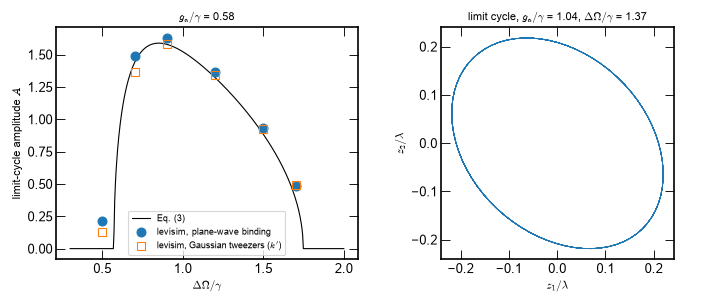

In [ ]:
ΔΩ_scan = np.array([0.5, 0.7, 0.9, 1.2, 1.5, 1.7]) * γ
scan_kwargs = dict(num_samples=50000, Δt=0.5 * μs, z_start=(150 * nm, 0.0))
scan = {field: [limit_cycle(0.58 * γ, ΔΩ, field, **scan_kwargs) for ΔΩ in ΔΩ_scan] for field in ('plane_wave', 'gaussian')}
check = limit_cycle(0.58 * γ, ΔΩ_scan[3], 'plane_wave', num_samples=100000, Δt=0.25 * μs, z_start=(150 * nm, 0.0))
print(f'time-step check at ΔΩ/γ = {ΔΩ_scan[3]/γ}: A = {scan["plane_wave"][3]["A"]:.4f} (Δt = 0.5 μs), {check["A"]:.4f} (0.25 μs)')
for field in scan:
    flagged = [f'{ΔΩ/γ:.2f}' for ΔΩ, r in zip(ΔΩ_scan, scan[field]) if abs(r['drift']) > 0.01 and r['A'] > 0.05]
    print(f'{field}: runs not settled to 1 % (ΔΩ/γ): {flagged or "none"}')
ΔΩ_fine = np.linspace(0.3, 2.0, 400) * γ
A_theory = np.array([eq3(0.58 * γ, ΔΩ)[0] for ΔΩ in ΔΩ_fine])
for field in scan:
    print(field, 'A (field phase gradient):', np.round([r['A_field'] for r in scan[field]], 3))
print('Eq. (3):                     ', np.round([eq3(0.58 * γ, ΔΩ)[0] for ΔΩ in ΔΩ_scan], 3))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
axes[0].plot(ΔΩ_fine / γ, A_theory, 'k-', label='Eq. (3)')
axes[0].plot(ΔΩ_scan / γ, [r['A_field'] for r in scan['plane_wave']], 'o', color='C0', label='levisim, plane-wave binding')
axes[0].plot(ΔΩ_scan / γ, [r['A_field'] for r in scan['gaussian']], 's', mfc='none', color='C1',
             label="levisim, Gaussian tweezers ($k'$)")
axes[0].set_xlabel(r'$\Delta\Omega/\gamma$')
axes[0].set_ylabel(r'limit-cycle amplitude $A$')
axes[0].set_title(r'$g_a/\gamma$ = 0.58', fontsize=10)
axes[0].legend(fontsize=8)
sim = results['plane_wave']['sim']
t = sim.time_array if hasattr(sim, 'time_array') else np.arange(sim.X.shape[0]) * 0.5 * μs
axes[1].plot(sim.X[-400:, 2] / λ, sim.X[-400:, 8] / λ, 'C0', lw=0.8)
axes[1].set_xlabel(r'$z_1/\lambda$')
axes[1].set_ylabel(r'$z_2/\lambda$')
axes[1].set_title(r'limit cycle, $g_a/\gamma$ = 1.04, $\Delta\Omega/\gamma$ = 1.37', fontsize=10)
axes[1].set_aspect('equal')
fig.tight_layout()

## 4. With thermal noise (Fig. 2, bottom row)

The same Gaussian system with the gas providing both the damping $\gamma$ and its thermal noise (293 K)
instead of cold damping. The paper's bottom row ($g_a/\gamma \approx 1.04$, $\Delta\Omega/\gamma \approx 1.37$) shows a
noisy limit cycle in the joint $z_1$-$z_2$ distribution; it attributes the difference between measured
and predicted amplitudes to these fluctuations. levisim's Gaussian model reaches at most
$g_a/\gamma$ = 0.99, which is used here.

noisy run: A (field phase gradient) = 2.96; deterministic run at the same point: 2.63
run time 653 s


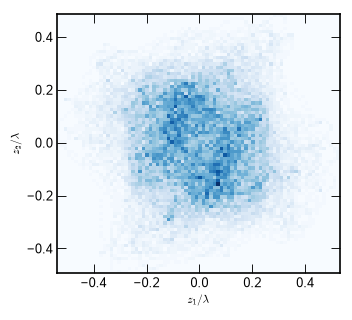

In [ ]:
noisy = limit_cycle(0.99 * ga_max['gaussian'], 1.37 * γ, 'gaussian', num_samples=60000, seed=3, noisy=True)
z1, z2 = noisy['sim'].X[20000:, 2], noisy['sim'].X[20000:, 8]
print(f'noisy run: A (field phase gradient) = {noisy["A_field"]:.2f}; deterministic run at the same point: '
      f'{limit_cycle(0.99 * ga_max["gaussian"], 1.37 * γ, "gaussian")["A_field"]:.2f}')
fig, ax = plt.subplots(figsize=(4.4, 4))
ax.hist2d(z1 / λ, z2 / λ, bins=80, cmap='Blues')
ax.set_xlabel(r'$z_1/\lambda$')
ax.set_ylabel(r'$z_2/\lambda$')
ax.set_aspect('equal')
fig.tight_layout()
print(f'run time {time.time() - T_START:.0f} s')

## Summary

**Agreements with Reisenbauer et al. (2024)**

- Coupling constant: with plane-wave tweezer fields levisim's $g_a$ is 0.972 of Eq. (M2). The 2.8 %
  difference is the radiation reaction in $\alpha$ (Im α/Re α = 0.039) plus $O(1/kd_0)$. With levisim's Gaussian
  tweezers $g_a$ is 0.772 of Eq. (M2), close to the Gouy factor $(k'/k)^2$ = 0.794 that Rudolph et al.'s
  Eq. (A4) predicts and Eq. (M2) leaves out.
- The largest $g_a/\gamma$ at the stated parameters (trap power calibrated to the measured 27.5 kHz) is 0.99
  (Gaussian) or 1.25 (plane wave). The largest measured value is 1.04 ± 0.08, so the model is consistent
  with the strongest coupling the paper reports.
- Exceptional points: at $g_a/\gamma$ = 0.58 levisim's full drift matrix (no rotating-wave approximation) has
  degenerate frequencies for $0.03 \le \Delta\Omega/\gamma \le 2.332$, with $4g_a/\gamma$ = 2.332. The paper measured
  $0 < \Delta\Omega/\gamma \lesssim 2.3$ (Fig. 3a). The lower edge is the grid step. The damping rates split by
  at most 3.998 $g_a$, at $\Delta\Omega$ = 2.05 $g_a$ (paper: $4g_a$ at $2g_a$).
- Limit cycles from the nonlinear time domain: at the bottom row of Fig. 2 ($g_a/\gamma$ = 1.04,
  $\Delta\Omega/\gamma$ = 1.37), with plane-wave binding, $A$ = 2.753 against 2.726 from Eq. (3) (+1.0 %) and
  $\psi$ = 1.868 against 1.881. With Gaussian tweezers ($g_a/\gamma$ = 0.95), $A$ = 2.566 measured with $k'$
  against 2.560 (+0.2 %), $\psi$ = 1.853. Along $\Delta\Omega$ at $g_a/\gamma$ = 0.58 (Fig. 3b), the settled
  amplitudes are 0.3-5.5 % above Eq. (3) inside the Hopf region (3-5.5 % with plane-wave binding): 1.628 against 1.579 at $\Delta\Omega/\gamma$ = 0.9,
  and 1.366 against 1.322 at 1.2. The time step changes $A$ by 0.7 % from 0.5 μs to 0.25 μs. Eq. (3) is a
  cycle-averaged model, so its $O(g_a/\Omega_0)$ corrections and the trap nonlinearity, which the full
  simulation keeps, are the expected size of this difference.
- The limit cycle is a tilted ellipse in the $z_1$-$z_2$ plane with amplitudes of about $0.22\lambda$, as in
  Fig. 2c (bottom). With the gas noise the cycle is broadened, and the mean amplitude rises from 2.63 to
  2.96. The paper too attributes its measured amplitudes above Eq. (3) to thermal fluctuations.

**Differences and limits**

- The trap power is calibrated to the measured frequency, because levisim's paraxial trap at the
  stated 0.3 W gives 71.3 kHz rather than 27.5 kHz. The coupling strength is then set by the angle of
  the separation axis, standing in for the paper's half-wave plate.
- The two runs nearest the thresholds ($\Delta\Omega/\gamma$ = 0.5 and 1.7, and 0.7 with Gaussian tweezers) had
  not settled within 25 ms, because of critical slowing down. Their amplitudes are upper bounds that
  were still decaying.
- Sign convention: levisim's $g_a$ has the sign of Rieser et al. (2022) and Rudolph et al. (2024) for
  $\phi_1 - \phi_2$, while this paper writes the same formula with $\phi_2 - \phi_1$.
- Not reproduced: the measured amplitudes $\bar A$ and phase histograms, which would need the paper's
  data, and correlated recoil noise between the particles (Rudolph et al., Eq. (8)). Liška et al. (2024)
  is also not reproduced, because of its standing-wave geometry and $kR \approx 1.2$.